# P4 프로젝트: 와인 품질 예측

포르투갈의 화이트 와인 품질 데이터를 이용하여 **결정 트리, 배깅, 랜덤 포레스트, 그레이디언트 부스팅, XGBoost**를 비교한다.

> **같은 와인의 화학적 특성으로 품질 점수를 예측하는 회귀 모델과, 품질이 6점 이상인지 구분하는 분류 모델을 만들면 어떤 차이가 나타나는가?**

P4 실습에서는 트리의 분할과 깊이, 배깅의 표본추출, 랜덤 포레스트의 무작위 특성 선택, 그레이디언트 부스팅의 순차 학습을 살펴보았다. 이번 프로젝트에서는 **같은 데이터 분할과 평가 기준**으로 여러 모델을 비교하고, 모델 선택의 근거를 설명한다.

코드는 출발점으로 제공한다. 그래프와 점수만 보고 답을 정하기보다, **왜 그런 결과가 나타났는지** 자신의 말로 기록하자.

**코드 실행**

[(구글 코랩) P4 프로젝트: 와인 품질 예측](https://colab.research.google.com/github/codingalzi/code-workout-ml/blob/master/p4_project_wine_quality.ipynb)에서 코드를 실행할 수 있다.

**프로젝트 진행 원칙**

1. **훈련·검증·최종 테스트 데이터를 구분한다.** 테스트셋은 회귀와 분류의 모델 선택을 모두 마친 뒤에만 성능을 확인한다.
2. **입력 특성에 `quality`를 포함하지 않는다.** 분류용 `high_quality`도 `quality`에서 만들어지므로 입력에 넣어서는 안 된다.
3. **회귀와 분류를 구분해서 평가한다.** RMSE와 F1은 서로 다른 과제의 지표이므로 직접 비교하지 않는다.
4. **동일한 데이터 분할에서 모델을 비교한다.** 성능 차이를 임의의 분할 차이로 착각하지 않는다.
5. **AI를 활용해도 개념적 판단은 직접 검증한다.** 하이퍼파라미터, 모델 선택, 특성 중요도 해석의 근거를 남긴다.

**환경설정**

In [1]:
import sys
import sklearn
from packaging.version import Version

assert sys.version_info >= (3, 10)
assert Version(sklearn.__version__) >= Version("1.6.1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
plt.rc("font", size=12)
plt.rc("axes", labelsize=13, titlesize=13)
plt.rc("legend", fontsize=11)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.8.0


## 1단계 — 문제 정의, 데이터 이해, EDA

### 두 가지 예측 문제를 설계한다

- **샘플:** 화이트 와인 한 건의 화학적 특성과 품질 평가 기록
- **입력 특성:** 알코올, 산도, 밀도 등 **11개 수치형 특성**
- **회귀 타깃:** 전문가 평가 점수 `quality` 자체
- **분류 타깃:** `quality >= 6`이면 1, 아니면 0인 **프로젝트용 이진 레이블**
- **양성 클래스(1):** 품질 점수 6 이상

이번 프로젝트에서 '고품질'은 **6점 이상으로 정한 분석상 기준**이지, 원자료에 별도 표시된 와인 등급이 아니다. `quality`는 정수 점수이므로 회귀 결과를 해석할 때 **순서형 평가를 수치형 값처럼 예측하고 있다는 한계**도 고려해야 한다.

### 데이터셋과 특성 소개

**Wine Quality**는 포르투갈 *Vinho Verde* 와인의 이화학적 검사 결과와 관능 품질 점수를 포함한다. 이번 프로젝트는 **화이트 와인 4,898개 기록**을 사용한다(레드 와인 데이터는 사용하지 않음).

| 특성 | 의미 | 특성 | 의미 |
|---|---|---|---|
| `fixed acidity` | 고정 산도 | `volatile acidity` | 휘발성 산도 |
| `citric acid` | 구연산 | `residual sugar` | 잔당 |
| `chlorides` | 염화물 | `free sulfur dioxide` | 유리 이산화황 |
| `total sulfur dioxide` | 총 이산화황 | `density` | 밀도 |
| `pH` | 수소이온농도 지수 | `sulphates` | 황산염 |
| `alcohol` | 알코올 함량 | `quality` | **타깃**: 품질 점수 |

**프로젝트 기록 ① — 분석 설계**

- 회귀 문제와 이진분류 문제의 차이:
- 6점을 분류 기준으로 정한 이유 또는 이 기준의 한계:
- 같은 입력 특성으로 두 문제를 풀 수 있는 이유:
- 실제 예측 시점에 알 수 있는 입력 정보는 무엇인가?:

### UCI에서 데이터를 불러온다

원본 파일은 세미콜론(`;`)으로 구분된다. 같은 폴더에 CSV 파일이 있으면 그 파일을 먼저 사용하고, 없다면 공식 UCI 압축파일에서 화이트 와인 데이터를 읽는다.

In [2]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

csv_path = Path("winequality-white.csv")

if csv_path.exists():
    df_raw = pd.read_csv(csv_path, sep=";")
else:
    uci_url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
    try:
        with urlopen(uci_url, timeout=30) as response:
            content = response.read()
        with ZipFile(BytesIO(content)) as archive:
            csv_member = next(name for name in archive.namelist()
                              if name.endswith("winequality-white.csv"))
            with archive.open(csv_member) as file:
                df_raw = pd.read_csv(file, sep=";")
    except Exception as exc:
        raise RuntimeError(
            "UCI 데이터 다운로드에 실패했습니다. Wine Quality 데이터셋의 "
            "winequality-white.csv를 내려받아 노트북과 같은 폴더에 놓아주세요."
        ) from exc

print("원본 데이터 크기:", df_raw.shape)
df_raw.head()

원본 데이터 크기: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


### 열과 자료형, 결측값, 중복 행을 확인한다

In [3]:
expected_features = [
    "fixed acidity", "volatile acidity", "citric acid", "residual sugar",
    "chlorides", "free sulfur dioxide", "total sulfur dioxide",
    "density", "pH", "sulphates", "alcohol"
]
assert set(expected_features + ["quality"]) == set(df_raw.columns)
print("열별 자료형:\n", df_raw.dtypes)
print("\n결측값 개수:\n", df_raw.isna().sum())
print("\n완전히 동일한 행의 중복 개수:", df_raw.duplicated().sum())

열별 자료형:
 fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

결측값 개수:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

완전히 동일한 행의 중복 개수: 937


### 동일한 행을 제거한 뒤 데이터를 나눈다

원자료에는 **모든 열의 값이 완전히 동일한 행**이 포함될 수 있다. 이번 프로젝트에서는 동일 행이 훈련셋과 테스트셋 양쪽에 들어가 성능을 과도하게 좋게 보이게 할 가능성을 줄이기 위해, **분할하기 전에 완전히 동일한 행만 제거**한다.

다만 값이 같은 와인이 실제로 서로 다른 관측 사례일 수도 있다. 중복 제거가 언제나 정답은 아니며, 이번 프로젝트의 평가 대상이 **중복을 제거한 기록들**로 바뀐다는 점을 이해해야 한다. 특성만 같고 점수가 다른 행은 이 코드에서 제거하지 않는다.

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("중복 제거 전:", len(df_raw))
print("중복 제거 후:", len(df))
print("제거한 행:", len(df_raw) - len(df))

assert df[expected_features + ["quality"]].notna().all().all()

중복 제거 전: 4898
중복 제거 후: 3961
제거한 행: 937


### 최종 테스트셋을 먼저 보존한다

훈련·검증·테스트셋을 대략 **60% / 20% / 20%**로 분할한다. 분류할 때 양성 클래스 비율이 지나치게 달라지지 않도록 `quality >= 6` 레이블을 이용해 **층화 분할**(stratified split)한다.

회귀에서도 **동일한 행의 분할**을 사용한다. 결과의 공정한 비교를 위해 분류와 회귀에서 데이터를 따로 무작위로 나누지 않는다.

**주의:** `stratify`를 분할에 사용하는 것은 타깃을 입력 특성에 포함하는 것과 다르다. 모델의 입력에는 타깃이나 분류 레이블이 들어가지 않는다.

In [5]:
from sklearn.model_selection import train_test_split

binary_label = (df["quality"] >= 6).astype(int)
dev_df, test_df = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE,
    stratify=binary_label
)
train_df, val_df = train_test_split(
    dev_df, test_size=0.25, random_state=RANDOM_STATE,
    stratify=(dev_df["quality"] >= 6).astype(int)
)
print("훈련:", train_df.shape, "검증:", val_df.shape,
      "최종 테스트:", test_df.shape)
print("※ 최종 테스트셋의 점수 분포·성능은 선택을 마칠 때까지 확인하지 않는다.")

훈련: (2376, 12) 검증: (792, 12) 최종 테스트: (793, 12)
※ 최종 테스트셋의 점수 분포·성능은 선택을 마칠 때까지 확인하지 않는다.


### 훈련 데이터만 탐색한다

먼저 훈련 데이터의 품질 점수 분포를 확인한다. 같은 점수라도 관측 개수가 다를 수 있어 분류에서는 **클래스 비율**이 중요하다.

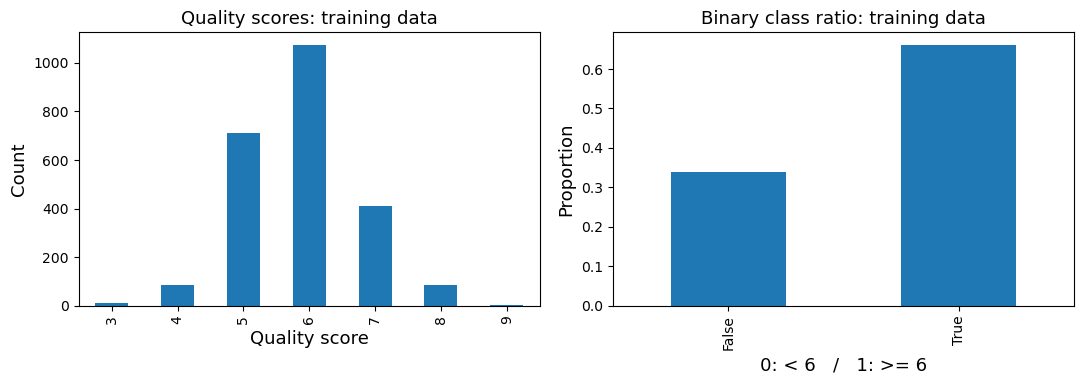

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df["quality"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Quality scores: training data")
axes[0].set_xlabel("Quality score")
axes[0].set_ylabel("Count")
(train_df["quality"] >= 6).value_counts(normalize=True).sort_index().plot.bar(ax=axes[1])
axes[1].set_title("Binary class ratio: training data")
axes[1].set_xlabel("0: < 6   /   1: >= 6")
axes[1].set_ylabel("Proportion")
plt.tight_layout()
plt.show()

### 특성과 품질 점수의 관계를 관찰한다

`alcohol`과 `volatile acidity`의 분포가 품질 점수별로 어떻게 다른지 살펴보자. 그래프는 **상관관계나 예측에 도움이 될 가능성**을 보여줄 수 있지만 인과관계를 증명하지는 못한다.

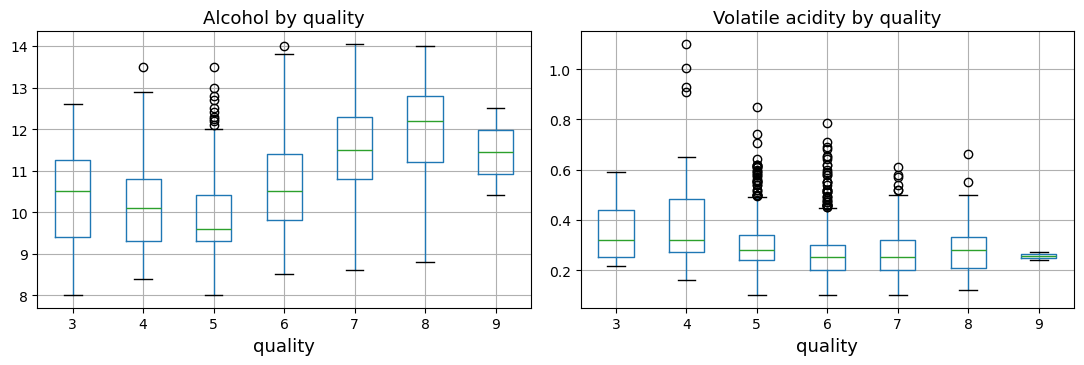

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df.boxplot(column="alcohol", by="quality", ax=axes[0])
train_df.boxplot(column="volatile acidity", by="quality", ax=axes[1])
axes[0].set_title("Alcohol by quality")
axes[1].set_title("Volatile acidity by quality")
plt.suptitle("")
plt.tight_layout()
plt.show()

### 나만의 EDA 질문을 만든다

`density`, `residual sugar`, `pH`, `sulphates` 등에서 하나 이상 선택해 **훈련 데이터만** 탐색한다.

- **나의 질문:**
- **그 질문을 확인하기 위한 그래프:**
- **관찰 결과:**
- **모델링에 주는 시사점:**

In [8]:
# TODO: 위에서 정한 EDA 질문을 확인하는 코드를 작성한다.
# 예: train_df.groupby(...)[...].mean()

### 프로젝트 기록 ② — 데이터 이해와 모델링 가설

- 원본 행 수와 중복 제거 후 행 수:
- 분류의 양성 클래스 비율:
- 품질 점수에서 가장 많이 관측되는 값:
- 특성과 품질 점수 사이에서 관찰한 관계 두 가지:
- 트리 모델에서 표준화가 반드시 필요한지에 대한 생각:

### AI 체크포인트 ① — EDA 검토

EDA 코드와 해석을 AI에게 검토받아도 된다. **훈련 데이터만 사용했는지**, 상관관계를 인과관계로 단정하지 않았는지, 클래스 비율을 정확히 해석했는지 직접 확인한다.

### 입력과 두 종류의 타깃을 만든다

입력 특성은 **11개 화학적 특성**으로 고정한다. 분류용 타깃은 `quality`에서 만들지만, 입력에는 넣지 않는다. 동일한 행의 분할을 사용하므로 회귀와 분류의 분석 결과를 일관되게 비교할 수 있다.

In [9]:
feature_cols = expected_features

X_train = train_df[feature_cols]
X_val = val_df[feature_cols]
y_train_reg = train_df["quality"]
y_val_reg = val_df["quality"]
y_train_clf = (y_train_reg >= 6).astype(int)
y_val_clf = (y_val_reg >= 6).astype(int)

assert "quality" not in X_train.columns
assert X_train.columns.tolist() == X_val.columns.tolist()
print("입력 특성 수:", X_train.shape[1])
print("훈련/검증 샘플 수:", len(X_train), len(X_val))

입력 특성 수: 11
훈련/검증 샘플 수: 2376 792


**1단계 마무리 체크**

- 11개 특성이 모두 수치형이라는 사실과 타깃의 차이
- 중복 기록이 평가에 영향을 줄 수 있는 이유
- 훈련·검증·테스트를 분리해야 하는 이유
- 회귀 타깃과 이진분류 타깃을 구분해야 하는 이유

## 2단계 — 회귀: 결정 트리와 앙상블 모델 비교

먼저 `quality` 점수를 직접 예측하는 회귀 문제를 다룬다. 예측된 값이 정수가 아니어도 **회귀 예측값을 억지로 반올림하지 않고** RMSE·MAE를 계산한다. 순서형 점수를 수치형처럼 취급하는 모델링 선택이라는 점은 최종 해석에서 다룬다.

### 기준선과 결정 트리 깊이를 비교한다

- **DummyRegressor:** 특성을 보지 않고 평균 점수를 예측하는 기준선
- **DecisionTreeRegressor:** 잎 노드 안의 훈련 점수 평균으로 예측
- `max_depth=2`, `3`, 제한 없음: **분할이 세밀해지면 훈련·검증 성능이 어떻게 달라지는가?**

P4 실습의 깊이 2·3 비교를 실제 회귀 문제로 확장해 보자.

### 배깅, 랜덤 포레스트, 그레이디언트 부스팅과 XGBoost

- **배깅:** 부트스트랩으로 조금씩 다른 데이터를 학습한 트리들의 예측을 평균한다.
- **랜덤 포레스트:** 각 트리의 **노드마다** 무작위 후보 특성을 고려하며, 회귀에서는 예측값을 평균한다.
- **그레이디언트 부스팅:** 이전 예측의 오류를 줄이도록 트리를 **순서대로 추가**한다.
- **XGBoost:** 규제·학습 효율화 등을 포함한 부스팅 구현이다.

모델별 하이퍼파라미터를 무조건 동일하게 맞춰야 공정한 것은 아니다. **같은 데이터와 평가 절차**를 적용한 뒤, 결과를 근거로 비교한다.

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.base import clone

try:
    from xgboost import XGBRegressor, XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("XGBoost 미설치: 해당 모델을 건너뜁니다. 필요하면 %pip install xgboost 실행 후 다시 시작하세요.")

reg_models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Tree (depth=2)": DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
    "Tree (depth=3)": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Tree (unlimited)": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
        n_estimators=100, max_samples=0.8, bootstrap=True,
        oob_score=True, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=2, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=2,
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting (slow)": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        random_state=RANDOM_STATE
    )
}
if HAS_XGBOOST:
    reg_models["XGBoost"] = XGBRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=3,
        objective="reg:squarederror", tree_method="hist",
        random_state=RANDOM_STATE, n_jobs=2
    )
print("비교할 회귀 모델:", list(reg_models))

비교할 회귀 모델: ['Dummy', 'Tree (depth=2)', 'Tree (depth=3)', 'Tree (unlimited)', 'Bagging', 'Random Forest', 'Gradient Boosting', 'Gradient Boosting (slow)', 'XGBoost']


### 같은 기준으로 회귀 모델을 검증한다

- **훈련 RMSE:** 학습 데이터에 대한 오차
- **검증 RMSE:** 새로운 데이터에 대한 오차를 추정하기 위한 기준(작을수록 좋음)
- **MAE:** 평균적인 절대오차(점수 단위)
- **R²:** 타깃 변동에 대한 설명력. 음수가 나올 수도 있다.

**모델 선택의 1차 기준은 검증 RMSE**로 정한다.

In [11]:
reg_rows = []
for name, model in reg_models.items():
    model.fit(X_train, y_train_reg)
    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)
    reg_rows.append({
        "모델": name,
        "훈련 RMSE": root_mean_squared_error(y_train_reg, pred_train),
        "검증 RMSE": root_mean_squared_error(y_val_reg, pred_val),
        "검증 MAE": mean_absolute_error(y_val_reg, pred_val),
        "검증 R2": r2_score(y_val_reg, pred_val)
    })
reg_results = pd.DataFrame(reg_rows).set_index("모델").sort_values("검증 RMSE")
reg_results.round(3)

,훈련 RMSE,검증 RMSE,검증 MAE,검증 R2
모델,,,,
Bagging,0.324,0.715,0.546,0.363
Random Forest,0.336,0.718,0.550,0.357
XGBoost,0.620,0.720,0.554,0.353
Gradient Boosting,0.660,0.725,0.561,0.345
Gradient Boosting (slow),0.671,0.730,0.566,0.335
Tree (depth=3),0.735,0.805,0.626,0.191
Tree (depth=2),0.755,0.819,0.645,0.164
Dummy,0.887,0.896,0.678,-0.001
Tree (unlimited),0.000,1.025,0.715,-0.310


### 훈련·검증 오차와 모델 복잡도를 비교한다

깊이 제한이 없는 트리는 훈련 데이터에 매우 잘 맞을 수 있어. 그러나 **훈련 RMSE가 작다는 이유만으로 가장 좋은 모델은 아니다.**

C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\4233125495.py:6: UserWarning: Glyph 54984 (\N{HANGUL SYLLABLE HUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\4233125495.py:6: UserWarning: Glyph 47144 (\N{HANGUL SYLLABLE RYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\4233125495.py:6: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\4233125495.py:6: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\gslee\miniforge3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54984 (\N{HANGUL SYLLABLE HUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\gslee\miniforge3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47144 (\N

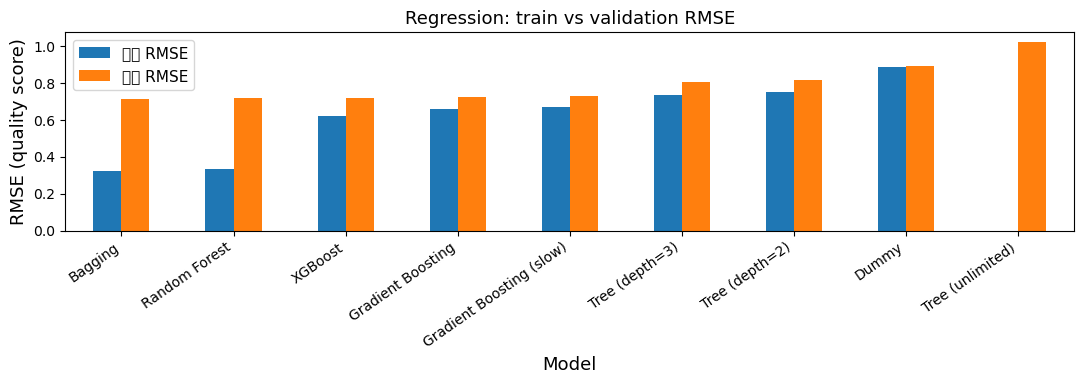

In [12]:
ax = reg_results[["훈련 RMSE", "검증 RMSE"]].sort_values("검증 RMSE").plot.bar(figsize=(11, 4))
ax.set_ylabel("RMSE (quality score)")
ax.set_title("Regression: train vs validation RMSE")
ax.set_xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 배깅과 랜덤 포레스트의 OOB 평가도 확인한다

`max_samples=0.8`인 배깅에서는 한 트리에 **전체 훈련 샘플 수의 약 80%만큼을 복원추출**한다. 이 경우 트리별 미추출(OOB) 샘플의 기대 비율은 약 `exp(-0.8) ≈ 44.9%`다.

랜덤 포레스트는 여기서 기본적으로 원본 훈련 크기만큼 복원추출하므로 OOB 기대 비율이 약 `exp(-1) ≈ 36.8%`다. `oob_score_`는 **트리별 OOB 비율이 아니라 OOB 예측을 이용한 회귀 R² 점수**라는 점을 구별하자.

In [13]:
print("Bagging OOB R2:", round(reg_models["Bagging"].oob_score_, 3))
print("Random Forest OOB R2:", round(reg_models["Random Forest"].oob_score_, 3))
print("검증 R2와 OOB R2는 다른 평가 방식의 결과입니다.")

Bagging OOB R2: 0.356
Random Forest OOB R2: 0.347
검증 R2와 OOB R2는 다른 평가 방식의 결과입니다.


### 랜덤 포레스트의 특성 중요도를 해석한다

`feature_importances_`는 불순도 감소에 기여한 정도를 나타낸다. **중요도가 크다고 해서 품질에 인과적인 영향을 준다고 결론 내릴 수는 없다.** 서로 상관된 특성 사이에서는 중요도가 나뉠 수도 있다.

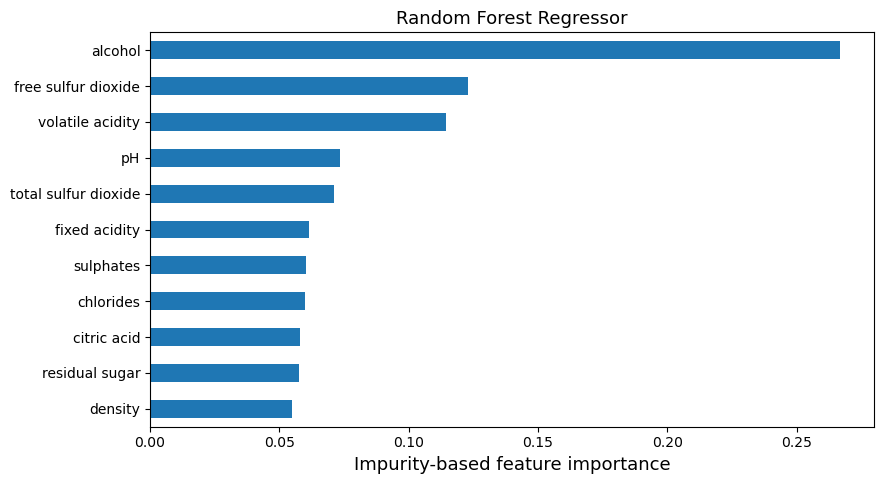

alcohol                 0.267
free sulfur dioxide     0.123
volatile acidity        0.114
pH                      0.074
total sulfur dioxide    0.071
dtype: float64

In [14]:
rf_reg = reg_models["Random Forest"]
rf_importance = pd.Series(rf_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)
rf_importance.sort_values().plot.barh(figsize=(9, 5))
plt.xlabel("Impurity-based feature importance")
plt.title("Random Forest Regressor")
plt.tight_layout()
plt.show()
rf_importance.head(5).round(3)

### 부스팅의 학습률과 트리 개수를 바꾸어 본다

P4 lab에서 **부스팅은 새 트리를 순차적으로 추가**한다고 배웠다. 아래에서는 `learning_rate`와 `n_estimators`를 같이 변경하여 검증 오차가 어떻게 달라지는지 확인한다. 이 실험은 **훈련·검증 데이터만** 사용한다.

In [15]:
boost_candidates = [
    {"n_estimators": 50, "learning_rate": 0.1},
    {"n_estimators": 100, "learning_rate": 0.1},
    {"n_estimators": 150, "learning_rate": 0.05},
]
boost_rows = []
for params in boost_candidates:
    model = GradientBoostingRegressor(max_depth=2, random_state=RANDOM_STATE, **params)
    model.fit(X_train, y_train_reg)
    boost_rows.append({
        **params,
        "훈련 RMSE": root_mean_squared_error(y_train_reg, model.predict(X_train)),
        "검증 RMSE": root_mean_squared_error(y_val_reg, model.predict(X_val))
    })
boost_results = pd.DataFrame(boost_rows).sort_values("검증 RMSE")
boost_results.round(3)

,n_estimators,learning_rate,훈련 RMSE,검증 RMSE
1,100,0.10,0.660,0.725
2,150,0.05,0.671,0.730
0,50,0.10,0.685,0.738


### 프로젝트 기록 ③ — 회귀 모델 비교

- 깊이 2와 깊이 3의 트리 구조 및 검증 RMSE 차이:
- 제한 없는 트리에서 확인한 과대적합 증거:
- 단일 트리와 배깅·랜덤 포레스트의 성능 차이:
- 배깅의 OOB R²와 검증 R²의 차이:
- 랜덤 포레스트 특성 중요도 상위 3개:
- 부스팅의 학습률·트리 개수 변경 결과:
- **가장 작은 검증 RMSE를 얻은 회귀 모델과 그 근거:**

### AI 체크포인트 ② — 회귀 결과 검토

AI의 해석을 참고하더라도 **훈련 성능과 검증 성능을 혼동하지 않았는지**, 특성 중요도를 인과효과라고 주장하지 않았는지, 테스트 결과를 사용하지 않았는지 확인한다.

## 3단계 — 분류: 같은 데이터로 품질 6점 이상 예측

회귀에서는 **품질 점수 자체**를 예측했고, 분류에서는 **품질 6점 이상 여부**를 예측한다.

타깃 변환은 다음과 같다.

$$ z_i = \begin{cases}1 & (\mathrm{quality}_i \ge 6)\\0 & (\mathrm{quality}_i < 6)\end{cases} $$

회귀로 얻은 예측값을 반올림해 분류하는 것이 아니라, **분류 모델을 별도로 학습**한다. 평가 지표도 달라져야 한다.

### 분류 모델을 준비한다

- **DummyClassifier:** 가장 흔한 클래스만 예측하는 기준선
- **결정 트리 깊이 2·3·제한 없음:** 분할 복잡도 비교
- **BaggingClassifier:** 각 트리가 복원추출한 학습 데이터를 이용
- **RandomForestClassifier:** 트리의 각 노드에서 분할 후보 특성을 무작위로 선택
- **GradientBoostingClassifier / XGBClassifier:** 분류 손실을 줄이도록 트리를 순차적으로 추가

분류의 `RandomForestClassifier`는 기본적으로 노드마다 후보 특성을 전체 특성 수의 제곱근 정도 고려한다. **BaggingClassifier의 `max_features=1.0`은 트리별로 모든 특성을 사용할 수 있다는 뜻**이므로 서로 구분한다.

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay
)

clf_models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Tree (depth=2)": DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    "Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Tree (unlimited)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, max_samples=0.8, max_features=1.0,
        bootstrap=True, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=2,
        random_state=RANDOM_STATE
    )
}
if HAS_XGBOOST:
    clf_models["XGBoost"] = XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3,
        objective="binary:logistic", eval_metric="logloss",
        tree_method="hist", random_state=RANDOM_STATE, n_jobs=2
    )
print("비교할 분류 모델:", list(clf_models))

비교할 분류 모델: ['Dummy', 'Tree (depth=2)', 'Tree (depth=3)', 'Tree (unlimited)', 'Bagging', 'Random Forest', 'Gradient Boosting', 'XGBoost']


### 정확도만으로 분류 모델을 선택하지 않는다

- **Accuracy:** 전체에서 맞게 예측한 비율
- **Precision:** 6점 이상이라고 예측한 와인 가운데 실제 6점 이상인 비율
- **Recall:** 실제 6점 이상인 와인 중 모델이 찾아낸 비율
- **F1:** Precision과 Recall의 조화평균
- **ROC-AUC:** 여러 임곗값에서의 구분 능력을 나타내는 지표

기본 임곗값 **0.5**에서 Accuracy, Precision, Recall, F1을 계산하고, ROC-AUC도 함께 살펴본다. 이번 프로젝트에서는 **검증 ROC-AUC를 1차 선택 기준**으로 정하고, Precision·Recall·F1을 함께 확인한다. 양성 클래스가 많은 데이터에서는 **모두 1로 예측하는 기준선도 F1이 높게 나올 수 있으므로** F1 하나만으로 선택하지 않는다.

In [17]:
clf_rows = []
for name, model in clf_models.items():
    model.fit(X_train, y_train_clf)
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    val_proba = model.predict_proba(X_val)[:, 1]
    clf_rows.append({
        "모델": name,
        "훈련 Accuracy": accuracy_score(y_train_clf, train_pred),
        "검증 Accuracy": accuracy_score(y_val_clf, val_pred),
        "검증 Precision": precision_score(y_val_clf, val_pred, zero_division=0),
        "검증 Recall": recall_score(y_val_clf, val_pred, zero_division=0),
        "검증 F1": f1_score(y_val_clf, val_pred, zero_division=0),
        "검증 ROC-AUC": roc_auc_score(y_val_clf, val_proba)
    })
clf_results = pd.DataFrame(clf_rows).set_index("모델").sort_values("검증 ROC-AUC", ascending=False)
clf_results.round(3)

,훈련 Accuracy,검증 Accuracy,검증 Precision,검증 Recall,검증 F1,검증 ROC-AUC
모델,,,,,,
Random Forest,0.986,0.782,0.818,0.860,0.838,0.847
Bagging,0.999,0.766,0.816,0.833,0.825,0.839
Gradient Boosting,0.800,0.768,0.801,0.862,0.830,0.825
XGBoost,0.829,0.766,0.807,0.849,0.827,0.825
Tree (depth=3),0.759,0.727,0.800,0.782,0.791,0.768
Tree (depth=2),0.748,0.725,0.744,0.887,0.809,0.740
Tree (unlimited),1.000,0.667,0.751,0.739,0.745,0.633
Dummy,0.660,0.659,0.659,1.000,0.795,0.500


### 결정 트리 복잡도와 분류 성능을 비교한다

회귀에서 보았던 **훈련·검증 성능의 차이**가 분류에서도 나타나는지 확인하자.

C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\1778464062.py:7: UserWarning: Glyph 54984 (\N{HANGUL SYLLABLE HUN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\1778464062.py:7: UserWarning: Glyph 47144 (\N{HANGUL SYLLABLE RYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\1778464062.py:7: UserWarning: Glyph 44160 (\N{HANGUL SYLLABLE GEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\gslee\AppData\Local\Temp\ipykernel_6988\1778464062.py:7: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\gslee\miniforge3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 54984 (\N{HANGUL SYLLABLE HUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\gslee\miniforge3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47144 (\N

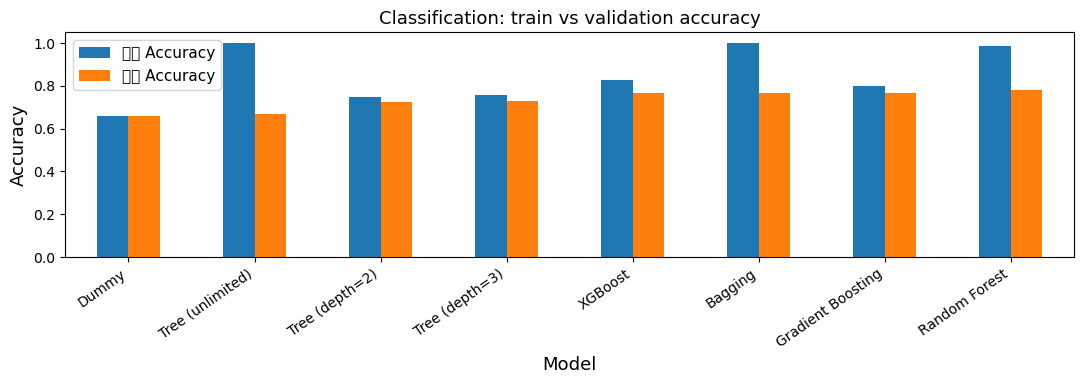

In [18]:
ax = clf_results[["훈련 Accuracy", "검증 Accuracy"]].sort_values("검증 Accuracy").plot.bar(figsize=(11, 4))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy")
ax.set_title("Classification: train vs validation accuracy")
ax.set_xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 프로젝트 기록 ④ — 분류 모델 비교

- 학습 데이터에서 `quality >= 6`의 비율:
- DummyClassifier의 검증 Accuracy와 F1:
- 결정 트리 깊이에 따른 훈련·검증 Accuracy의 변화:
- 배깅·랜덤 포레스트·부스팅·XGBoost의 검증 F1 차이:
- 검증 ROC-AUC가 높은 모델의 Precision과 Recall 사이의 관계:
- **검증 ROC-AUC와 F1 등을 근거로 선택한 분류 모델:**

### AI 체크포인트 ③ — 분류 결과 검토

AI가 '정확도가 가장 높은 모델이 가장 좋다'라고 설명하면 반박할 수 있는지 점검한다. **양성 클래스 비율, Precision, Recall, F1, ROC-AUC**를 구분하자.

## 4단계 — 최종 모델 선택과 테스트 평가

지금까지는 **훈련·검증 데이터만** 사용했다. 이제 회귀와 분류의 최종 모델을 선택하고 **선택을 확정한 뒤에만** 테스트셋에서 성능을 확인한다.

원한다면 검증 성능뿐 아니라 모델의 복잡도나 해석 가능성을 근거로 다른 모델을 고를 수 있다. 단, **최종 선택 근거를 테스트 성능을 보기 전에 기록**한다.

### 회귀·분류 모델을 확정한다

아래에서 각 모델명을 바꿀 수 있다. 선택한 모델의 하이퍼파라미터는 이미 위 `reg_models`, `clf_models`에 지정되어 있다.

In [19]:
suggested_reg_name = reg_results["검증 RMSE"].idxmin()
suggested_clf_name = clf_results["검증 ROC-AUC"].idxmax()

chosen_reg_name = suggested_reg_name  # TODO: 다른 모델을 선택하면 직접 수정
chosen_clf_name = suggested_clf_name  # TODO: 다른 모델을 선택하면 직접 수정

assert chosen_reg_name in reg_models
assert chosen_clf_name in clf_models
print("최종 회귀 모델:", chosen_reg_name)
print("최종 분류 모델:", chosen_clf_name)

최종 회귀 모델: Bagging
최종 분류 모델: Random Forest


### 프로젝트 기록 ⑤ — 최종 모델 선택 이유

- **회귀 모델:**
- **회귀 모델 선택 근거(검증 RMSE, 과대적합, 해석 가능성 등):**
- **분류 모델:**
- **분류 모델 선택 근거(검증 F1, Precision/Recall, 해석 가능성 등):**
- 같은 모델 종류가 회귀와 분류에서 모두 최적이었는가? 그렇지 않다면 가능한 이유는?:

**이 기록을 마친 뒤** 아래 테스트 셀을 실행한다.

### 개발 데이터 전체로 다시 학습하고 최종 테스트셋을 평가한다

검증셋을 포함하는 개발 데이터 전체로 **선택한 모델을 다시 훈련**한다. 테스트셋은 최종 평가에만 사용한다.

In [20]:
X_dev = dev_df[feature_cols]
y_dev_reg = dev_df["quality"]
y_dev_clf = (y_dev_reg >= 6).astype(int)

X_test = test_df[feature_cols]
y_test_reg = test_df["quality"]
y_test_clf = (y_test_reg >= 6).astype(int)

final_reg_model = clone(reg_models[chosen_reg_name])
final_clf_model = clone(clf_models[chosen_clf_name])
final_reg_model.fit(X_dev, y_dev_reg)
final_clf_model.fit(X_dev, y_dev_clf)

reg_test_pred = final_reg_model.predict(X_test)
clf_test_pred = final_clf_model.predict(X_test)
clf_test_proba = final_clf_model.predict_proba(X_test)[:, 1]

reg_test_scores = pd.Series({
    "RMSE": root_mean_squared_error(y_test_reg, reg_test_pred),
    "MAE": mean_absolute_error(y_test_reg, reg_test_pred),
    "R2": r2_score(y_test_reg, reg_test_pred)
}, name="회귀 테스트 성능")
clf_test_scores = pd.Series({
    "Accuracy": accuracy_score(y_test_clf, clf_test_pred),
    "Precision": precision_score(y_test_clf, clf_test_pred, zero_division=0),
    "Recall": recall_score(y_test_clf, clf_test_pred, zero_division=0),
    "F1": f1_score(y_test_clf, clf_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_clf, clf_test_proba)
}, name="분류 테스트 성능")

print("[회귀]", chosen_reg_name)
print(reg_test_scores.round(3))
print("\n[분류]", chosen_clf_name)
print(clf_test_scores.round(3))

[회귀] Bagging
RMSE    0.718
MAE     0.553
R2      0.357
Name: 회귀 테스트 성능, dtype: float64

[분류] Random Forest
Accuracy     0.760
Precision    0.803
Recall       0.843
F1           0.823
ROC-AUC      0.817
Name: 분류 테스트 성능, dtype: float64


### 회귀 예측 오차를 시각화한다

품질 점수가 낮거나 높은 와인에서 예측이 특히 어려운지 살펴본다. **평균으로만 예측하는 경향**이 있는지도 확인한다.

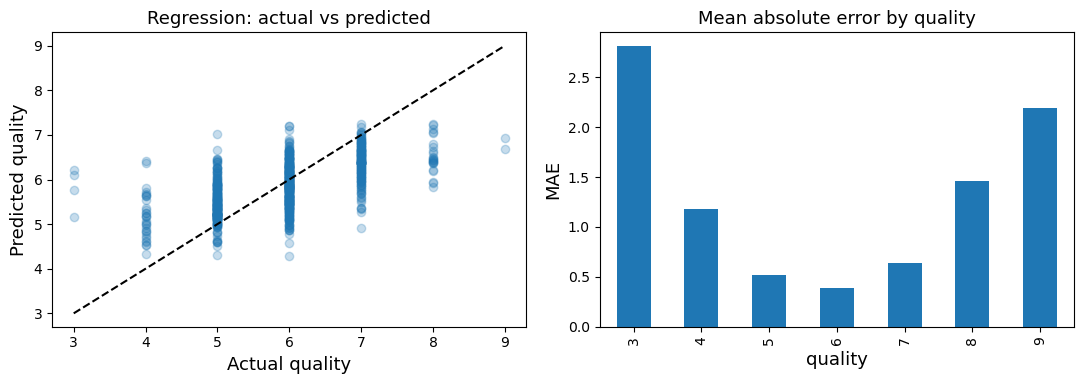

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test_reg, reg_test_pred, alpha=0.25)
lo = min(float(y_test_reg.min()), float(reg_test_pred.min()))
hi = max(float(y_test_reg.max()), float(reg_test_pred.max()))
axes[0].plot([lo, hi], [lo, hi], "k--")
axes[0].set_xlabel("Actual quality")
axes[0].set_ylabel("Predicted quality")
axes[0].set_title("Regression: actual vs predicted")

reg_errors = pd.DataFrame({
    "quality": y_test_reg.to_numpy(),
    "absolute_error": np.abs(y_test_reg.to_numpy() - reg_test_pred)
})
reg_errors.groupby("quality")["absolute_error"].mean().plot.bar(ax=axes[1])
axes[1].set_title("Mean absolute error by quality")
axes[1].set_ylabel("MAE")
plt.tight_layout()
plt.show()

### 분류의 혼동 행렬을 확인한다

**FP:** 실제 품질 6점 미만인데 모델이 6점 이상으로 분류한 경우.  
**FN:** 실제 품질 6점 이상인데 모델이 6점 미만으로 분류한 경우.

어떤 종류의 오류가 더 많은지 확인하고, 이번 프로젝트의 분류 목적에서 더 중요한 오류가 무엇일지 생각해 보자.

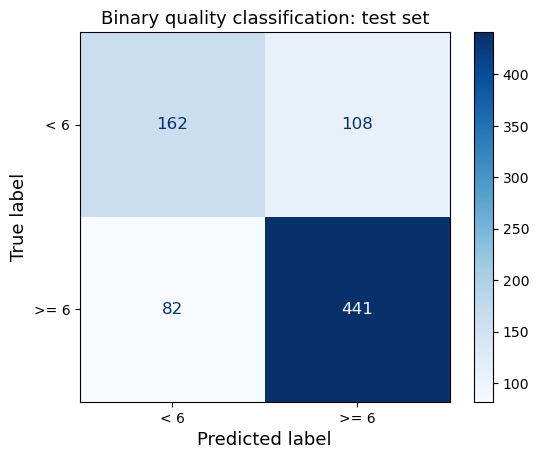

In [22]:
ConfusionMatrixDisplay.from_predictions(
    y_test_clf, clf_test_pred, display_labels=["< 6", ">= 6"],
    cmap="Blues", values_format="d"
)
plt.title("Binary quality classification: test set")
plt.show()

### 오류 사례와 해석의 한계를 살펴본다

회귀와 분류가 **서로 다른 목적**을 가진다는 점을 기억하자. 회귀에서 5.9점을 예측하는 것과 분류 모델이 '6점 이상'일 확률 0.9를 내는 것은 같은 주장이 아니다.

In [23]:
test_examples = X_test.copy()
test_examples["quality"] = y_test_reg.to_numpy()
test_examples["reg_pred"] = reg_test_pred
test_examples["reg_abs_error"] = np.abs(y_test_reg.to_numpy() - reg_test_pred)
test_examples["clf_proba_ge6"] = clf_test_proba
test_examples["clf_pred_ge6"] = clf_test_pred

test_examples.sort_values("reg_abs_error", ascending=False).head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,reg_pred,reg_abs_error,clf_proba_ge6,clf_pred_ge6
1037,8.3,0.33,0.42,1.15,0.033,18.0,96.0,0.99110,3.20,0.32,12.4,3,6.21,3.21,0.799238,1
2709,9.4,0.24,0.29,8.50,0.037,124.0,208.0,0.99395,2.90,0.38,11.0,3,6.11,3.11,0.675167,1
2535,6.1,0.20,0.34,9.50,0.041,38.0,201.0,0.99500,3.14,0.44,10.1,3,5.77,2.77,0.717167,1
3625,5.8,0.26,0.30,2.60,0.034,75.0,129.0,0.99020,3.20,0.38,11.5,4,6.41,2.41,0.980357,1
3064,7.4,0.27,0.31,2.40,0.014,15.0,143.0,0.99094,3.03,0.65,12.0,4,6.38,2.38,0.914083,1
1353,7.1,0.26,0.49,2.20,0.032,31.0,113.0,0.99030,3.37,0.42,12.9,9,6.68,2.32,0.970000,1
2097,7.3,0.17,0.24,8.10,0.121,32.0,162.0,0.99508,3.17,0.38,10.4,8,5.84,2.16,0.665278,1
871,7.9,0.64,0.46,10.60,0.244,33.0,227.0,0.99830,2.87,0.74,9.1,3,5.15,2.15,0.174667,0
499,6.3,0.27,0.38,0.90,0.051,7.0,140.0,0.99260,3.45,0.50,10.5,7,4.91,2.09,0.407929,0
718,8.1,0.27,0.35,1.70,0.030,38.0,103.0,0.99255,3.22,0.63,10.4,8,5.92,2.08,0.724500,1


### 프로젝트 기록 ⑥ — 최종 테스트 결과

- 선택한 회귀 모델의 테스트 RMSE·MAE와 그 의미:
- 선택한 분류 모델의 테스트 Accuracy·F1·ROC-AUC와 그 의미:
- 훈련·검증 성능과 테스트 성능 사이에 차이가 있는가?:
- 회귀에서 특히 예측하기 어려운 품질 점수 구간:
- 분류의 FP와 FN 중 더 중요하다고 생각하는 오류와 이유:
- 데이터 중복 제거, 임의 분할, 관능 평가 점수 등으로 인한 한계:

### AI 체크포인트 ④ — 최종 해석

AI가 테스트 결과를 근거로 모델이나 하이퍼파라미터를 다시 고치라고 제안하면, **그것은 최종 테스트셋을 모델 선택에 사용하게 된다는 점**을 지적할 수 있어야 한다. 새로운 방법을 검토하려면 별도의 새로운 평가 설계를 고려해야 한다.

### 예측과 인과관계를 구분한다

랜덤 포레스트에서 `alcohol`의 특성 중요도가 높았다고 가정해 보자. 이것이 **알코올 함량을 높이면 반드시 와인 품질이 좋아진다**는 뜻은 아니다. 와인에 관한 실제 실험이나 추가 근거 없이 예측 변수의 중요도를 원인으로 해석할 수 없다.

또한 이 데이터에는 포도 품종, 와인 브랜드, 생산 연도, 가격 같은 정보가 없으므로 그런 차이에 대한 효과를 이 프로젝트만으로 설명할 수 없다.

### 최종 결론을 작성한다

다음 항목을 포함하여 **근거 있는 결론**을 작성한다.

1. 두 예측 문제(품질 점수 회귀·6점 이상 이진분류)의 정의
2. 결정 트리 깊이에 따른 과대적합과 일반화 성능의 차이
3. 배깅·랜덤 포레스트·부스팅·XGBoost의 모델 학습 방식 차이와 검증 결과
4. 회귀와 분류 각각의 모델 선택 이유
5. 최종 테스트 성능과 오류 사례 분석
6. 특성 중요도에서 알 수 있는 것과 알 수 없는 것
7. 이번 실험의 한계와 후속 분석 아이디어

### 프로젝트 최종 제출 전 확인

- [ ] 화이트 와인 데이터의 11개 입력 특성과 `quality`를 구분했다.
- [ ] 분류 타깃 `quality >= 6`을 입력 특성으로 사용하지 않았다.
- [ ] 중복 행 처리와 데이터 분할 이유를 설명했다.
- [ ] 동일한 훈련·검증·테스트 분할로 두 예측 문제를 수행했다.
- [ ] 결정 트리의 깊이 2·3 및 무제한 모델을 비교했다.
- [ ] 배깅과 랜덤 포레스트의 차이, OOB 점수의 의미를 설명했다.
- [ ] 그레이디언트 부스팅과 XGBoost를 비교했다(XGBoost 미설치 시 그 이유 기록).
- [ ] 회귀는 RMSE, 분류는 ROC-AUC를 중심으로 검증 모델을 선택했다.
- [ ] 테스트셋을 최종 모델 선택에 사용하지 않았다.
- [ ] 특성 중요도를 인과관계로 해석하지 않았다.
- [ ] 그래프·수치에 근거한 최종 결론을 작성했다.

### 평가 기준

| 평가 영역 | 배점 | 확인할 내용 |
|---|---:|---|
| 문제 정의와 데이터 이해 | 4 | 회귀·분류 타깃 구분, 11개 특성, 중복 처리, 데이터 분할 |
| 결정 트리와 앙상블 비교 | 6 | 깊이·과대적합, 배깅·랜덤 포레스트·부스팅의 학습 원리와 성능 비교 |
| 모델 선택과 일반화 | 5 | 적절한 검증 지표, 최종 테스트 보호, 선택 근거 |
| 오류 및 특성 중요도 해석 | 3 | 품질 점수별 오차, FP·FN, 중요도와 인과관계 구분 |
| 최종 결론 | 2 | 결과에 기반한 독립적인 해석과 한계 논의 |
| **합계** | **20** |  |

## 선택 활동 — 검증 성능은 어떻게 바뀔까?

본문에서 정한 모델 후보와 비교한 다음, 아래 중 하나를 **선택**해 추가 실험을 수행하자.

- `RandomForestRegressor`의 `min_samples_leaf`를 `1`, `2`, `5`로 바꿔 검증 RMSE 비교
- `GradientBoostingClassifier`의 `learning_rate`와 `n_estimators` 조합을 바꿔 검증 F1 비교
- 랜덤 포레스트의 `feature_importances_`와 검증셋 **순열 중요도**(permutation importance) 비교

**실험은 훈련·검증 데이터에서만 수행한다.** 이미 확인한 테스트 점수에 맞춰 후보를 새로 선택하는 활동은 최종 평가 원칙에 어긋날 수 있으므로, 새로운 선택 실험은 별도 분석으로 다룬다.

In [24]:
# TODO: 선택 활동용 코드
# 예: 학습용 데이터에서 min_samples_leaf를 변경하고 검증 RMSE를 비교한다.